# Linear version of Reasoning-aware 3PL

In [2]:
## CONFIG
GH_NODES = 200
MAX_ITER = 200
MU_GAMMA = 0.1
MU_KAPPA = -0.01
KAPPA_MAX=-0.00001

OPTIMAL_KAPPA_INIT = True 

RIDGE_KAPPA = 0.1
RIDGE_GAMMA = 0.1
RIDGE_B = 0.1
RIDGE_A = 0.5
RIDGE_X0 = 1000

strict_Y_int = False

In [3]:
"""
todo : add seaborn, joblib, scipy in toml
"""

'\ntodo : add seaborn, joblib, scipy in toml\n'

In [4]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import joblib

# Graphical configs
# 1. Reset seaborn to baseline
sns.set_style('whitegrid')
sns.set_context('paper') # Remove font_scale!

# 2. Hardcode the absolute font sizes for publication
plt.rcParams.update({
    'font.size': 9,             # Global baseline
    'figure.titlesize': 9,      # Global figure titles (Added)
    'axes.titlesize': 10,       # Title of the subplot (ax.set_title)
    'axes.labelsize': 9,        # X and Y axis labels
    'xtick.labelsize': 8,       # Numbers on the X axis
    'ytick.labelsize': 8,       # Numbers on the Y axis
    'legend.fontsize': 8,       # Legend text
    'legend.title_fontsize': 8  # Legend title
})

### Data loading

In [5]:
B_coding = pd.read_csv('data/B_coding.csv', index_col=0)
B_language = pd.read_csv('data/B_language.csv', index_col=0)
B_reasoning = pd.read_csv('data/B_reasoning.csv', index_col=0)
B_math = pd.read_csv('data/B_math.csv', index_col=0)

Y_coding = pd.read_csv('data/Y_coding.csv', index_col=0)
Y_language = pd.read_csv('data/Y_language.csv', index_col=0)
Y_reasoning = pd.read_csv('data/Y_reasoning.csv', index_col=0)
Y_math = pd.read_csv('data/Y_math.csv', index_col=0)

c_coding = pd.read_csv('data/c_coding.csv', index_col=0).set_index('question_id')
c_language = pd.read_csv('data/c_language.csv', index_col=0).set_index('question_id')
c_reasoning = pd.read_csv('data/c_reasoning.csv', index_col=0).set_index('question_id')
c_math = pd.read_csv('data/c_math.csv', index_col=0).set_index('question_id')

In [6]:
B = pd.concat([B_language, B_coding, B_reasoning, B_math],axis=0)
Y = pd.concat([Y_language, Y_coding, Y_reasoning, Y_math],axis=0)
c = pd.concat([c_language, c_coding, c_reasoning, c_math],axis=0)

In [7]:
from reasoning_aware_irt.livebench_utils import reindex
_ = reindex(Y, B, c) # little helper to make sure that all dataframes have exactly the same sorted question_id indices

the model_id Y/B sequence is great!!
the question_id Y/B sequence is great!!
the question_id Y/c sequence is great!!


In [8]:
Y_ij = Y.values
B_ij = B.values.astype(int)
c_i = c.values.squeeze()

print(Y_ij.shape, B_ij.shape)
print(Y_ij.mean(), B_ij.mean())
print(c_i.shape, c_i[:5])

(786, 42) (786, 42)
0.39359059581389527 1310.9940930570701
(786,) [1.e-05 1.e-05 1.e-02 1.e-02 1.e-02]


In [9]:
model_list = np.array(list(B.columns)) 
print(model_list.shape, model_list[-5:])

(42,) ['baidu/ernie-4.5-21b-a3b-thinking' 'allenai/olmo-3-7b-think'
 'qwen/qwen3-30b-a3b-thinking-2507' 'google/gemma-3-27b-it:free'
 'meta-llama/llama-4-scout']


In [10]:
x0_j = np.log1p(B_ij.mean(axis=0)) # budget regularizer (Eq.12 in the paper)

# Evaluate with Reasoning-Aware 3PL's GEM : Linear Version

In [11]:
from reasoning_aware_irt.gem_quad import CalibrationData, CalibrationConfig
from reasoning_aware_irt.gem_quad import ReasoningAware3PLQuadraticCalibrator as ReasoningAware3PLCalibrator

data = CalibrationData(Y_ij=Y_ij, B_ij=B_ij, c_i=c_i)
cfg = CalibrationConfig()
cfg # lets see the default config


CalibrationConfig(gh_nodes=17, max_iter=50, tol=0.0001, seed=0, verbose=True, use_quadratic=True, use_pin_posthoc=False, optimal_kappa=False, tau=0.75, ridge_a=0.001, ridge_b=0.001, ridge_gamma=0.1, ridge_kappa=0.1, mu_a=1.0, mu_b=0.0, mu_gamma=0.2, mu_kappa=-0.02, a_min=0.05, a_max=5.0, gamma_min=0.0, gamma_max=2.0, kappa_min=-2.0, kappa_max=-1e-06, x0_j=None, ridge_x0=0.1)

In [12]:
%%time
init_param_dict = None
    
cfg = CalibrationConfig(
gh_nodes=GH_NODES, max_iter=MAX_ITER, verbose=True,
ridge_kappa=RIDGE_KAPPA, ridge_gamma=RIDGE_GAMMA, 
ridge_a=RIDGE_A, mu_gamma=MU_GAMMA, ridge_b=RIDGE_B,
mu_kappa=MU_KAPPA, kappa_max=KAPPA_MAX, tol=0.001,
ridge_x0=RIDGE_X0, x0_j=x0_j, optimal_kappa=OPTIMAL_KAPPA_INIT,
use_quadratic=False # ENABLE linear mode here
)

calibrator = ReasoningAware3PLCalibrator(cfg)
print(cfg)

CalibrationConfig(gh_nodes=200, max_iter=200, tol=0.001, seed=0, verbose=True, use_quadratic=False, use_pin_posthoc=False, optimal_kappa=True, tau=0.75, ridge_a=0.5, ridge_b=0.1, ridge_gamma=0.1, ridge_kappa=0.1, mu_a=1.0, mu_b=0.0, mu_gamma=0.1, mu_kappa=-0.01, a_min=0.05, a_max=5.0, gamma_min=-0.5, gamma_max=2.0, kappa_min=-2.0, kappa_max=-1e-05, x0_j=array([6.35004162, 7.18324597, 6.22199298, 6.10262406, 6.08033779,
       6.31970369, 6.66785474, 5.85850006, 6.37936752, 6.09960554,
       5.78765811, 5.83985728, 5.87082677, 6.04222478, 5.90920246,
       5.76998548, 6.39809522, 6.28766226, 6.65008317, 7.12763448,
       5.98803629, 6.62097526, 5.86790868, 5.80626863, 5.67414051,
       6.33643609, 5.74972923, 6.22767251, 6.46911815, 6.46083781,
       6.523779  , 6.19990512, 5.95793145, 6.17126225, 8.08663221,
       7.75749563, 8.41777231, 8.89141742, 9.26252837, 8.86775312,
       7.09789816, 6.60762969]), ridge_x0=1000)
CPU times: user 479 μs, sys: 77 μs, total: 556 μs
Wall time:

In [13]:

fit_results = calibrator.fit(data, strict_Y_int=strict_Y_int, init_param_dict=init_param_dict)

iter   1  ll=-15062.013825   dLL=nan
iter   2  ll=-13907.349267   dLL=nan
iter   3  ll=-13853.638699   dLL=5.371e+01
iter   4  ll=-13830.701707   dLL=2.294e+01
iter   5  ll=-13819.896727   dLL=1.080e+01
iter   6  ll=-13814.846768   dLL=5.050e+00
iter   7  ll=-13811.207552   dLL=3.639e+00
iter   8  ll=-13808.677235   dLL=2.530e+00
iter   9  ll=-13808.301895   dLL=3.753e-01
iter  10  ll=-13807.500489   dLL=8.014e-01
iter  11  ll=-13805.750757   dLL=1.750e+00
iter  12  ll=-13805.988679   dLL=-2.379e-01
iter  13  ll=-13806.868009   dLL=-8.793e-01
iter  14  ll=-13807.371111   dLL=-5.031e-01
iter  15  ll=-13807.452079   dLL=-8.097e-02
iter  16  ll=-13807.244579   dLL=2.075e-01
iter  17  ll=-13807.060363   dLL=1.842e-01
iter  18  ll=-13806.936624   dLL=1.237e-01
iter  19  ll=-13806.609471   dLL=3.272e-01
iter  20  ll=-13806.455678   dLL=1.538e-01
iter  21  ll=-13806.295884   dLL=1.598e-01
iter  22  ll=-13806.124650   dLL=1.712e-01
iter  23  ll=-13806.071652   dLL=5.300e-02
iter  24  ll=-13806

In [14]:
fit_results.info['c_i'] = c_i
fit_results.info['B_ij'] = B_ij

# Explore Output
we can investigate the 1st-pass output below, but it's not final yet, as its likelihood will be improved further with post-hoc refinement and then next GEM passes (see the notebook `fig2_posthoc.ipynb` )

In [15]:
from reasoning_aware_irt.posthoc import print_model_summary
data2 = print_model_summary(model_list, fit_results, Y_ij, sort_by="best_theta")

Meta-Llama-3.1-405B-Instruct-Turbo  | BaseTheta:   0.10 ± 0.055| Gamma: -0.0157 ± 0.0695| Kappa: -0.0000 ± nan |Avg Y :   0.456
Best Budget:   nan|BestTheta:     nan ±     nan|Avg. EffTheta:  -0.000 ±     nan|

Meta-Llama-3.1-70B-Instruct-Turbo   | BaseTheta:  -0.33 ± 0.061| Gamma: -0.0104 ± 0.0378| Kappa: -0.0000 ± nan |Avg Y :   0.402
Best Budget:   nan|BestTheta:     nan ±     nan|Avg. EffTheta:  -0.406 ±     nan|

Phi-3-medium-128k-instruct          | BaseTheta:  -1.72 ± 0.124| Gamma: -0.0013 ± 0.0920| Kappa: -0.0000 ± nan |Avg Y :   0.238
Best Budget:   nan|BestTheta:     nan ±     nan|Avg. EffTheta:  -1.724 ±     nan|

Phi-3-medium-4k-instruct            | BaseTheta:  -1.58 ± 0.123| Gamma: -0.0041 ± 0.0978| Kappa: -0.0000 ± nan |Avg Y :   0.251
Best Budget:   nan|BestTheta:     nan ±     nan|Avg. EffTheta:  -1.609 ±     nan|

Phi-3-mini-128k-instruct            | BaseTheta:  -2.38 ± 0.142| Gamma: -0.0058 ± 0.0967| Kappa: -0.0000 ± nan |Avg Y :   0.190
Best Budget:   nan|BestTheta

## Post-hoc Refinement (Appendix B)
The visualization below exactly performs the $M-quantile\ partition$ explained in Appendix B, where $M=8$. For each subplot, the legend "latent" denotes $\hat{z}^{(m)}_j$.

In [16]:
from reasoning_aware_irt.posthoc import plot_sliced_bins

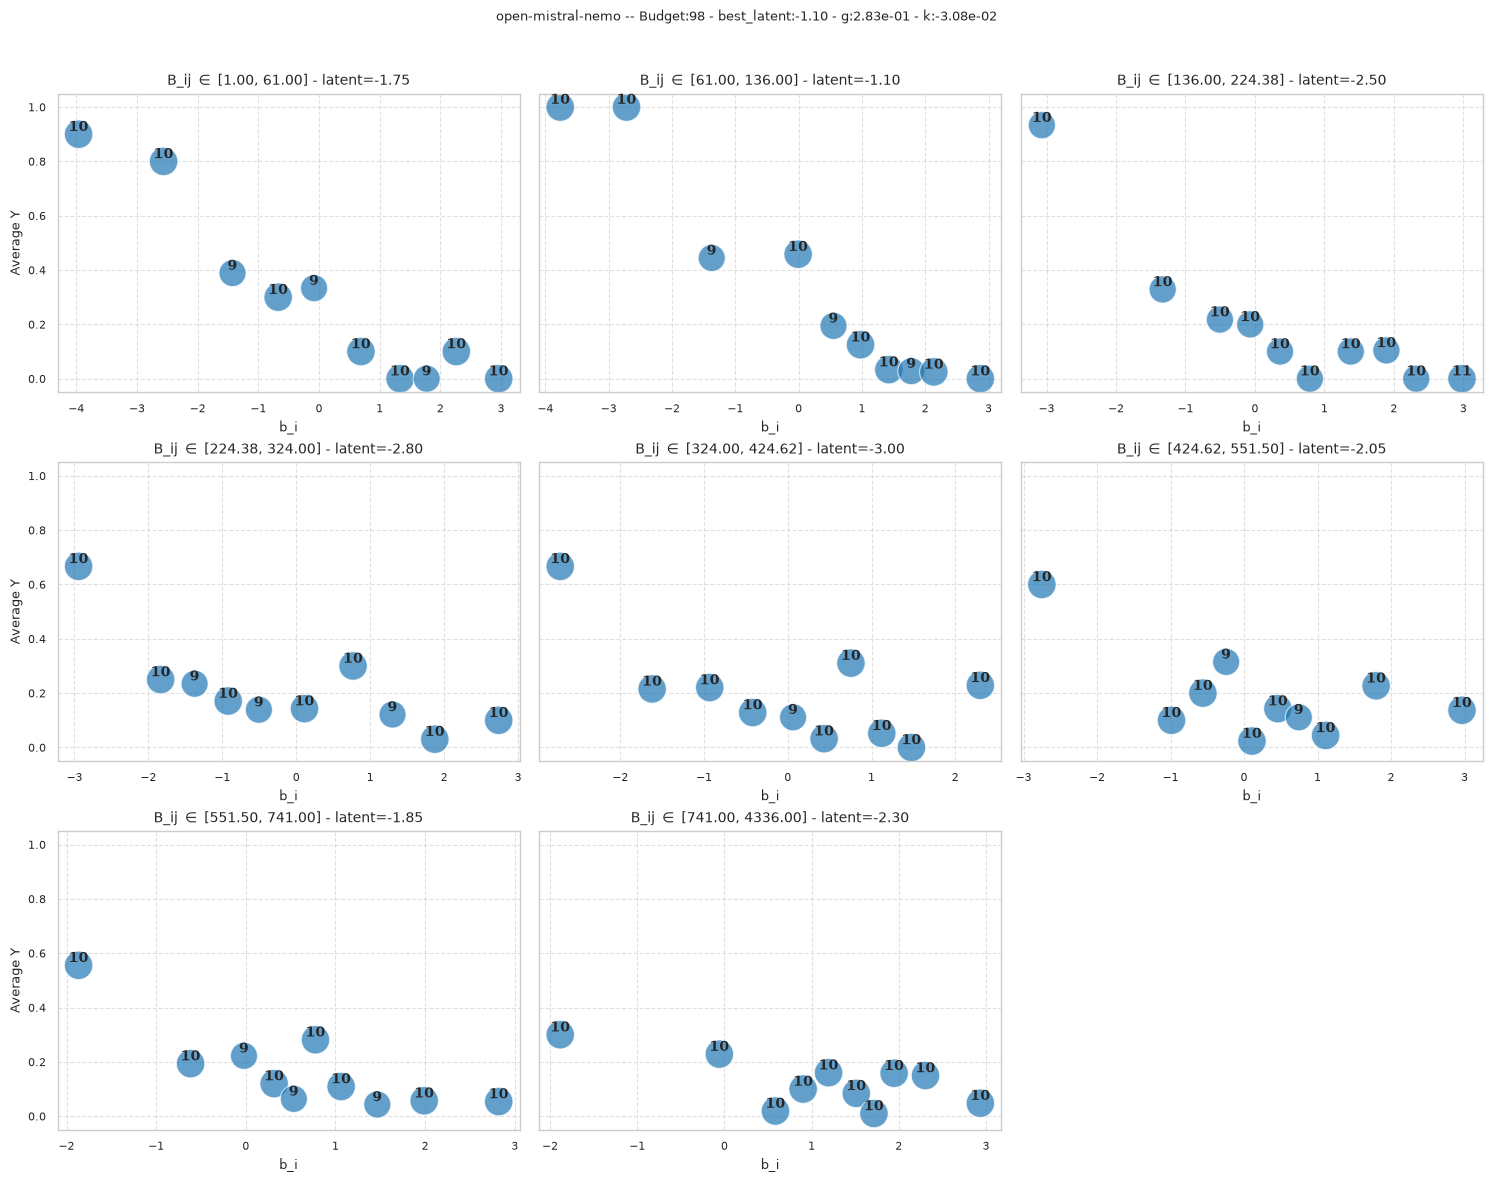

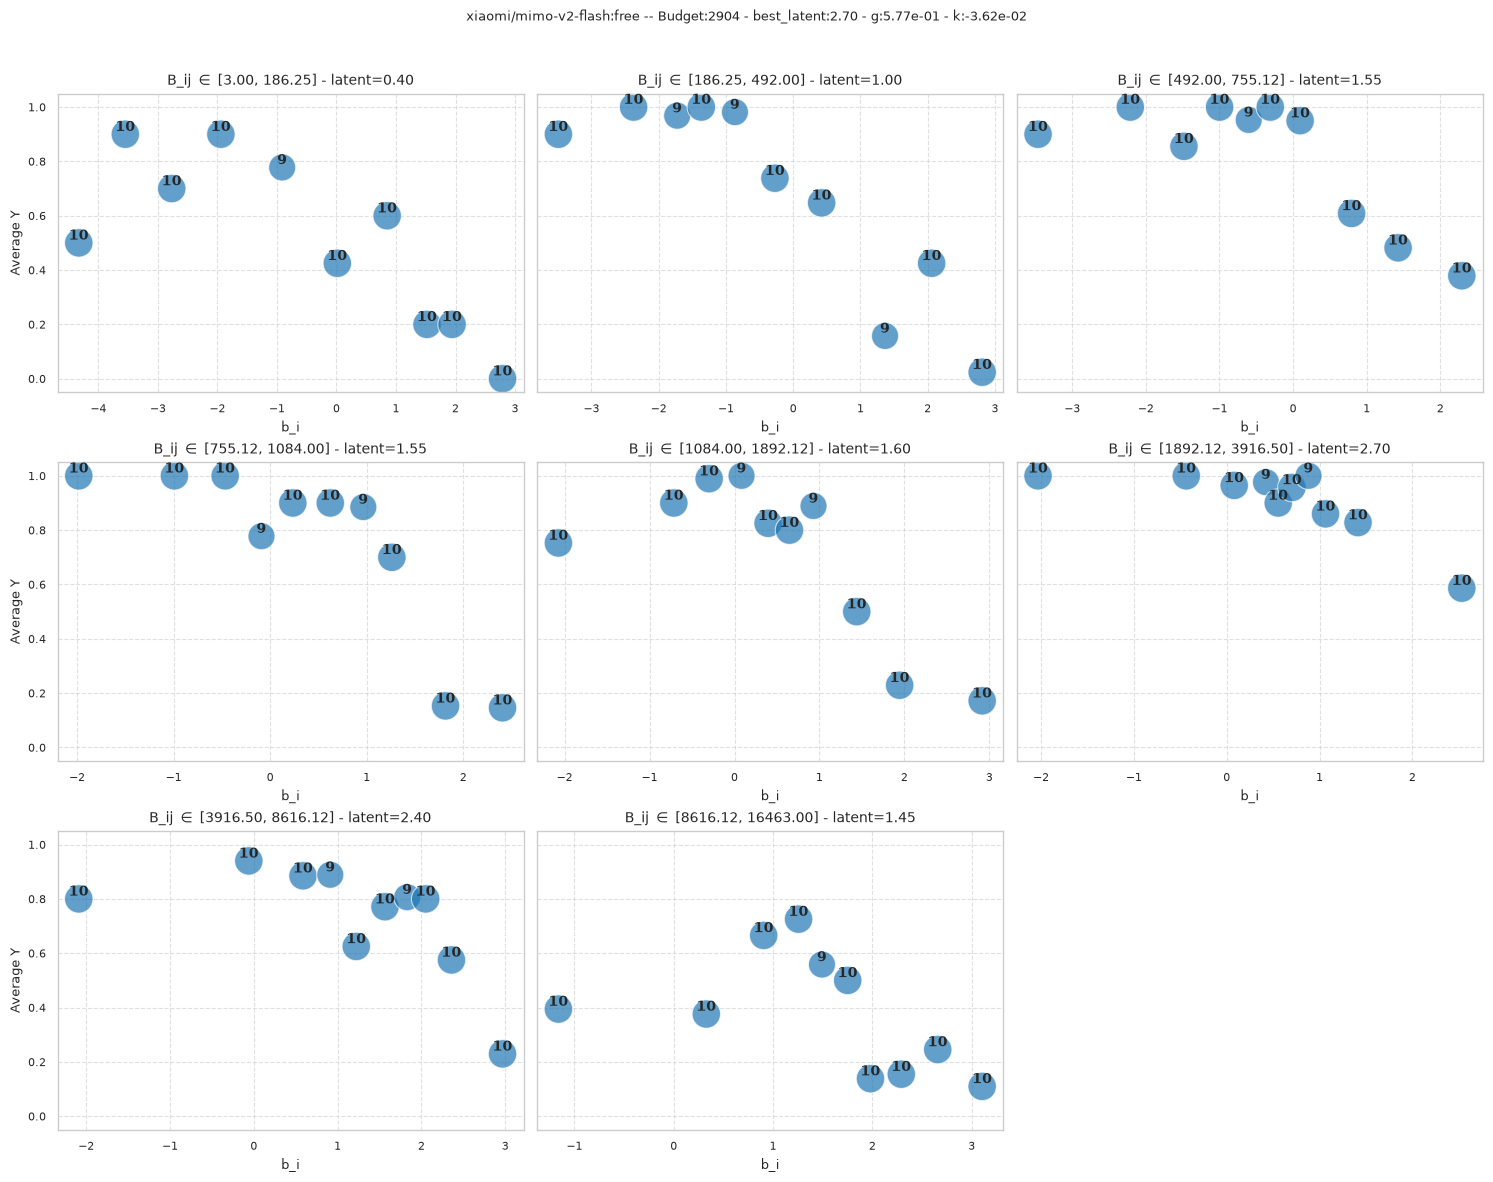

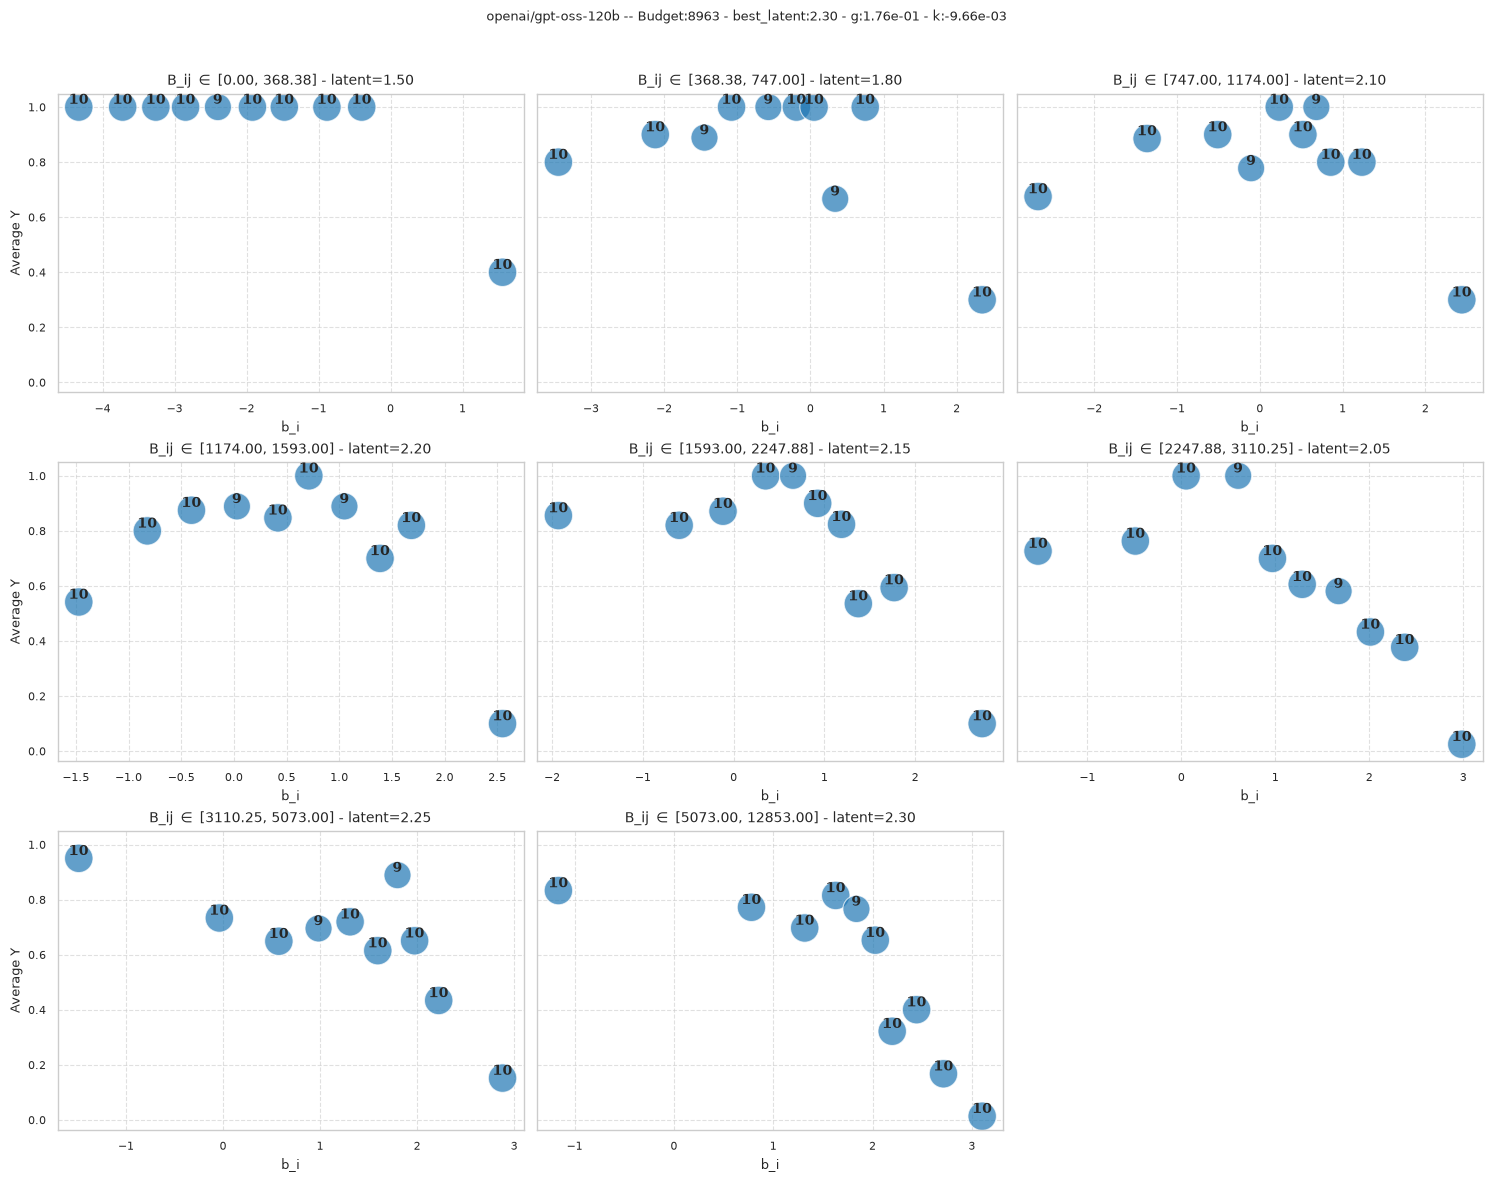

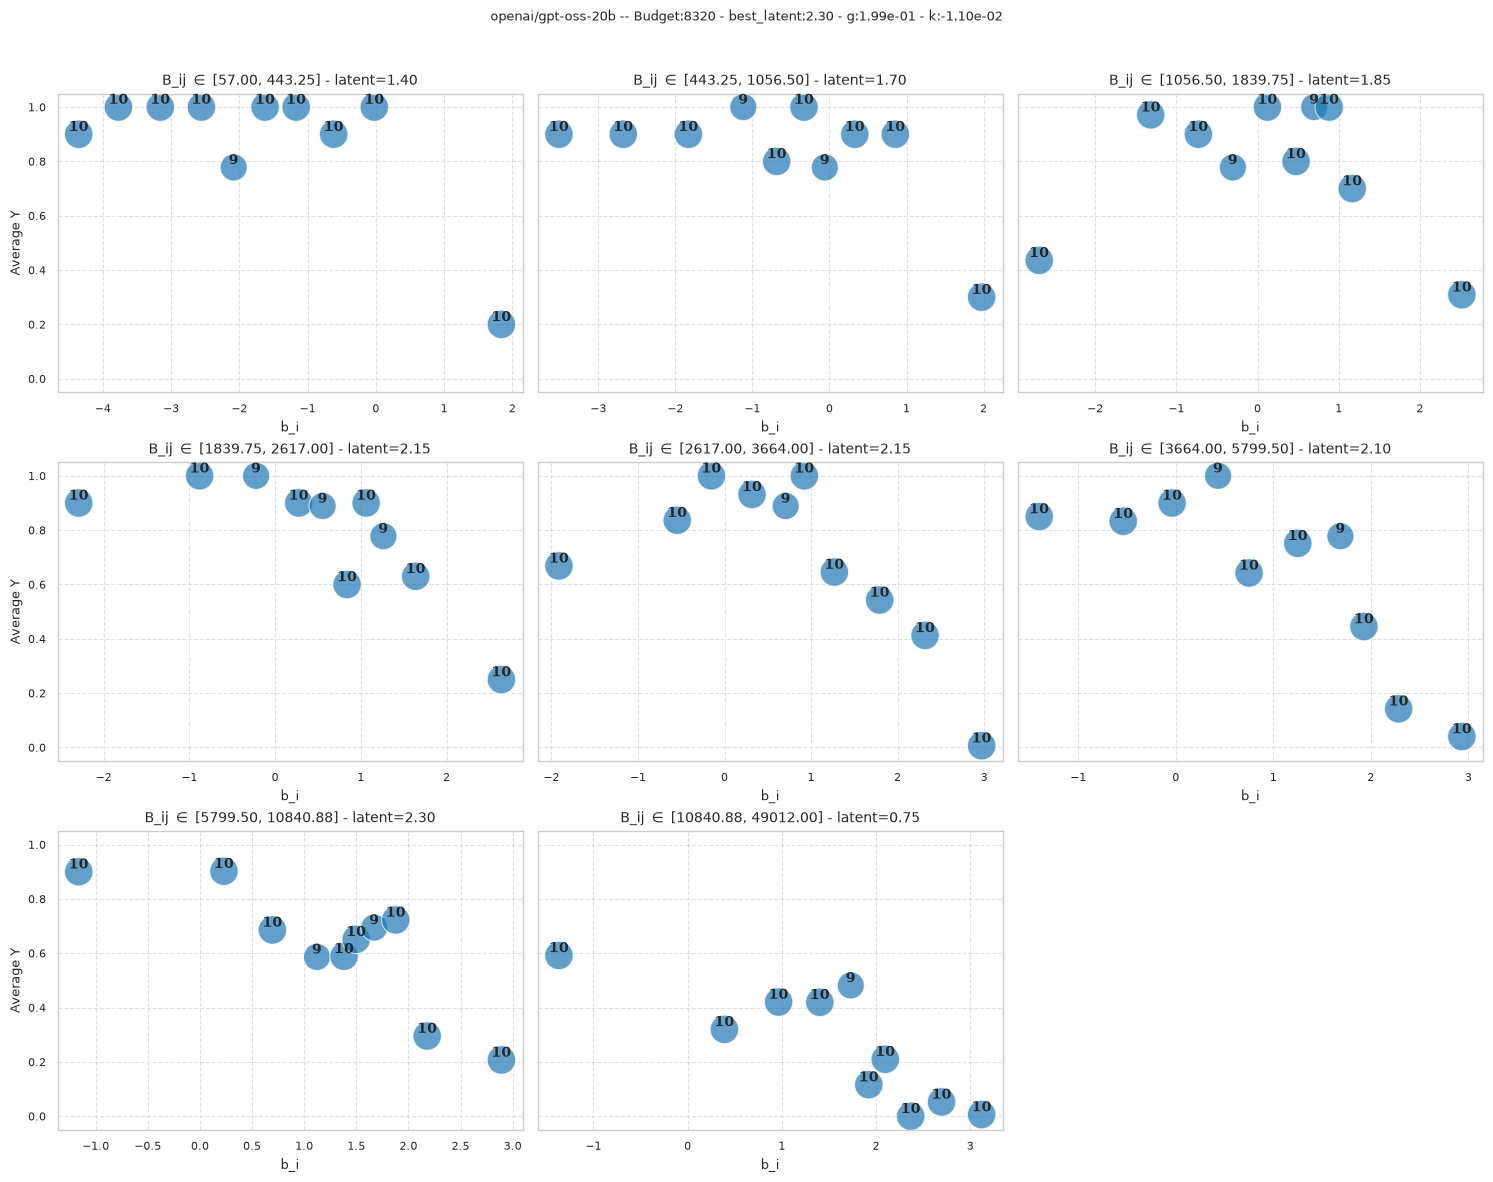

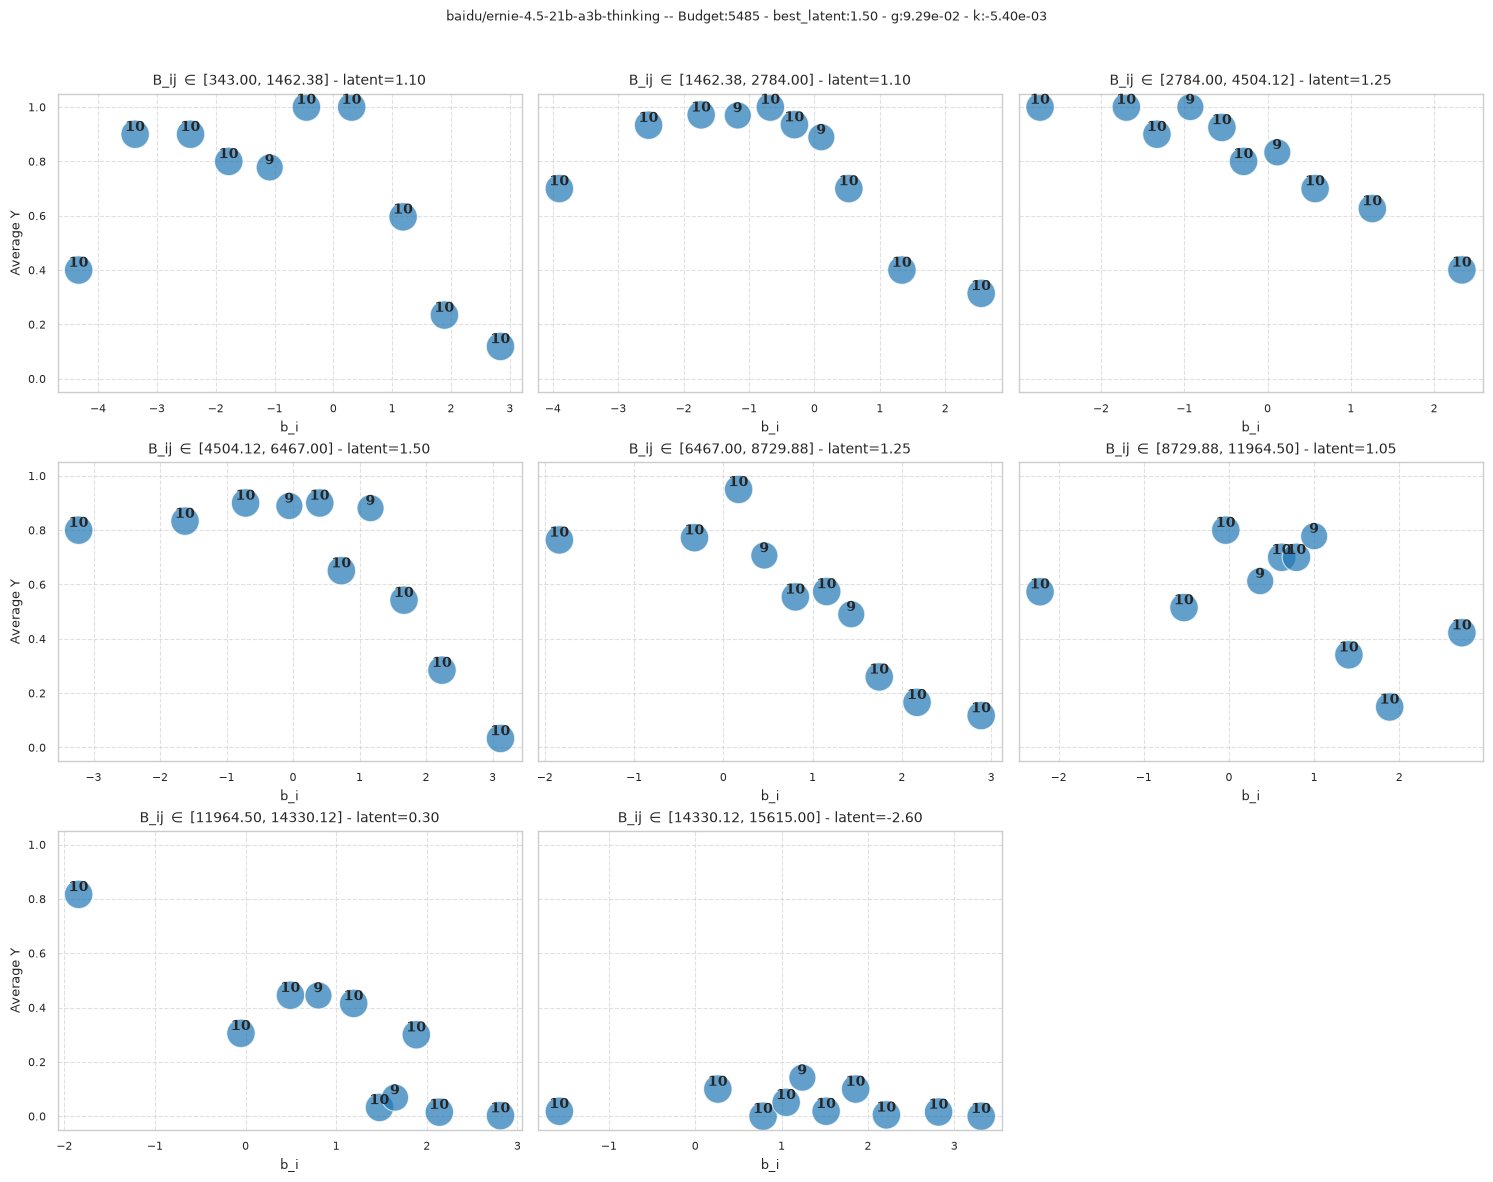

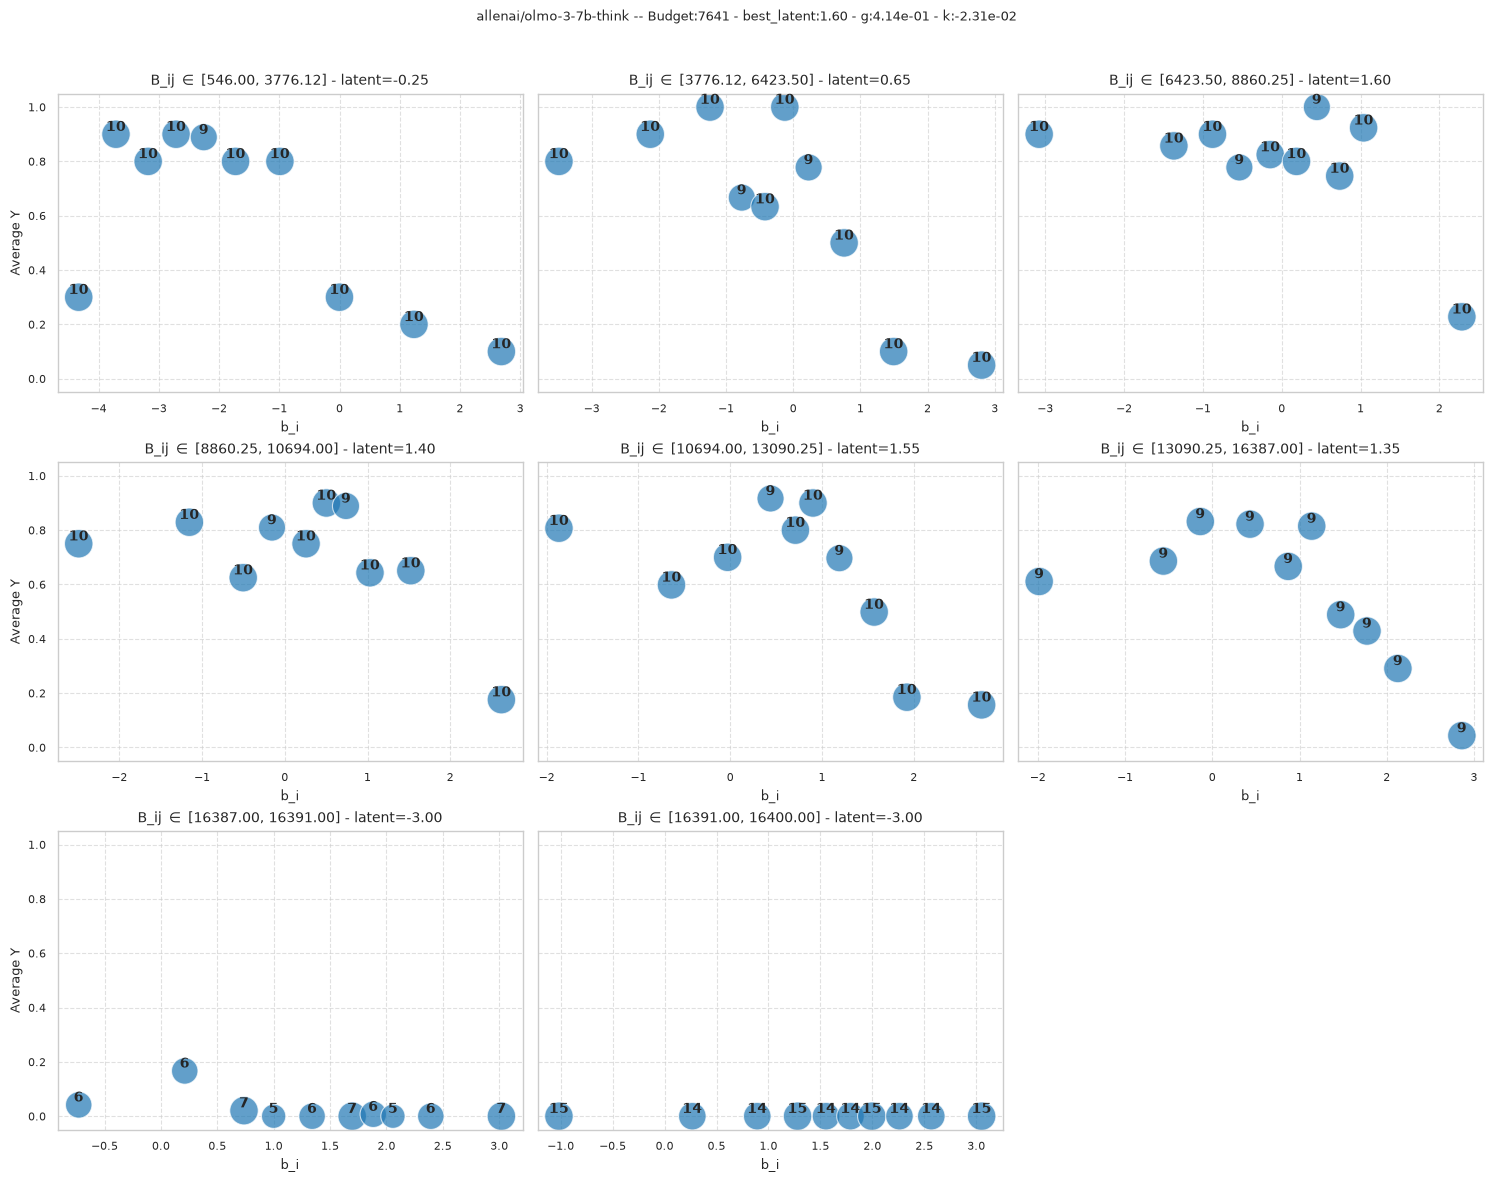

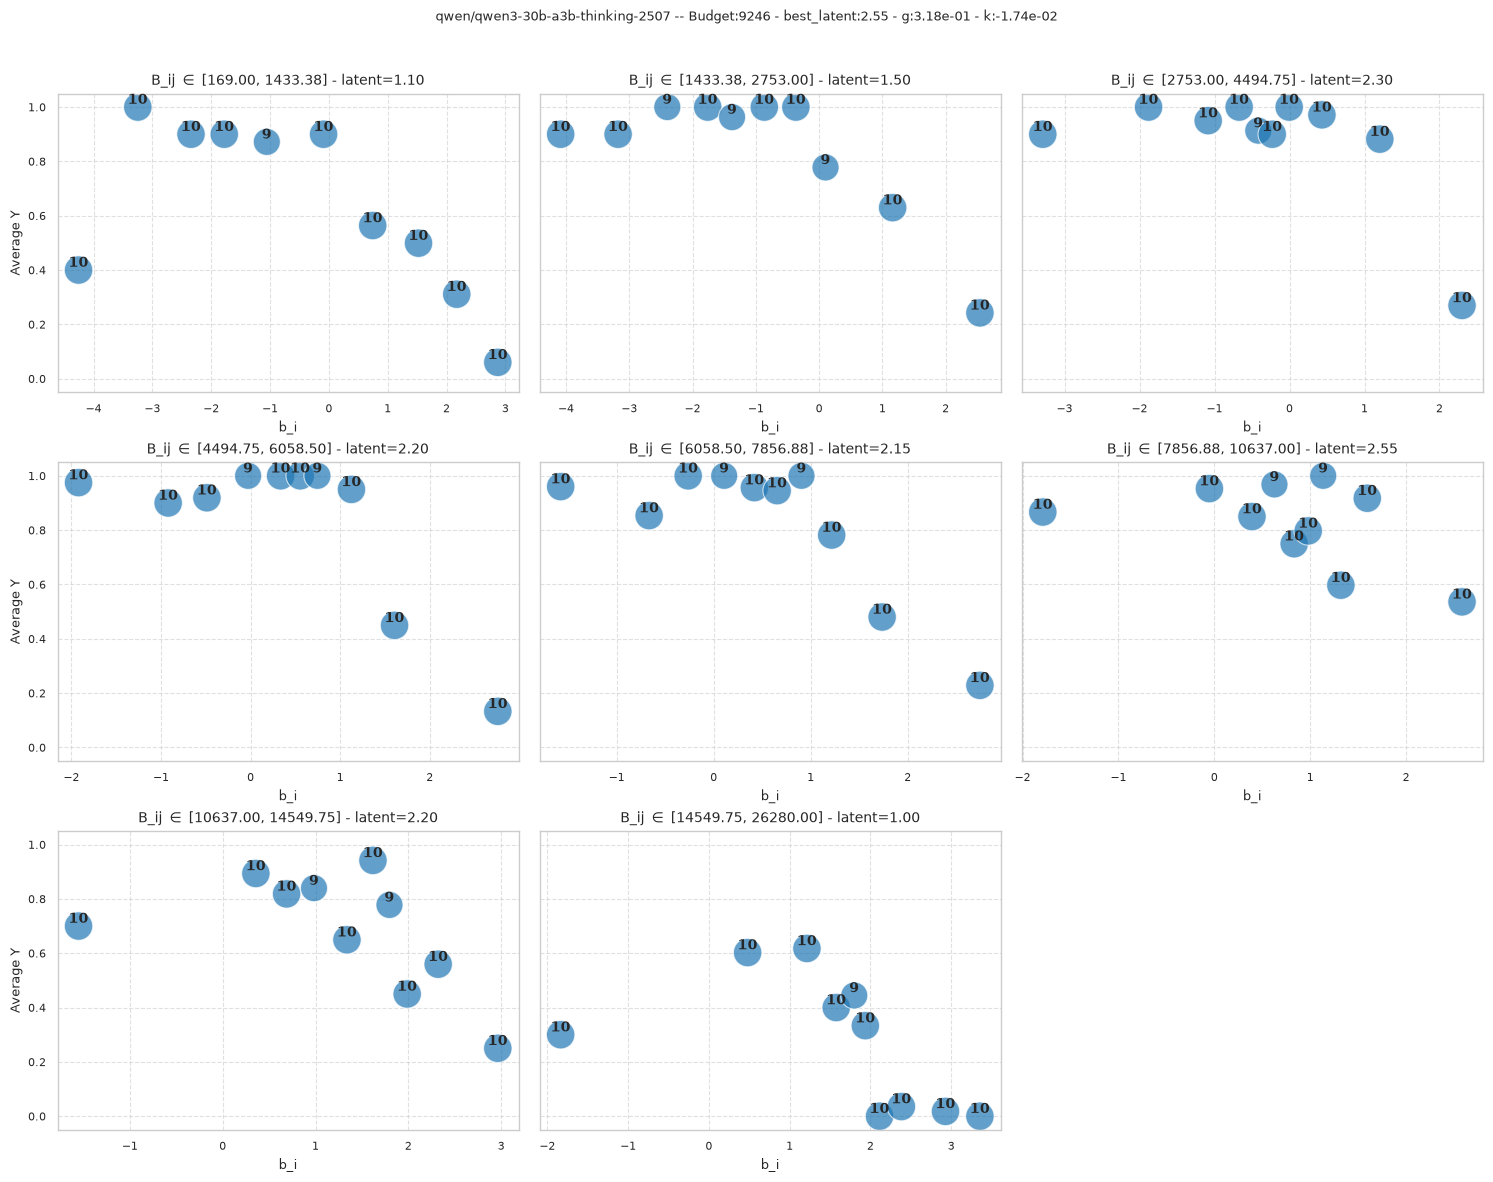

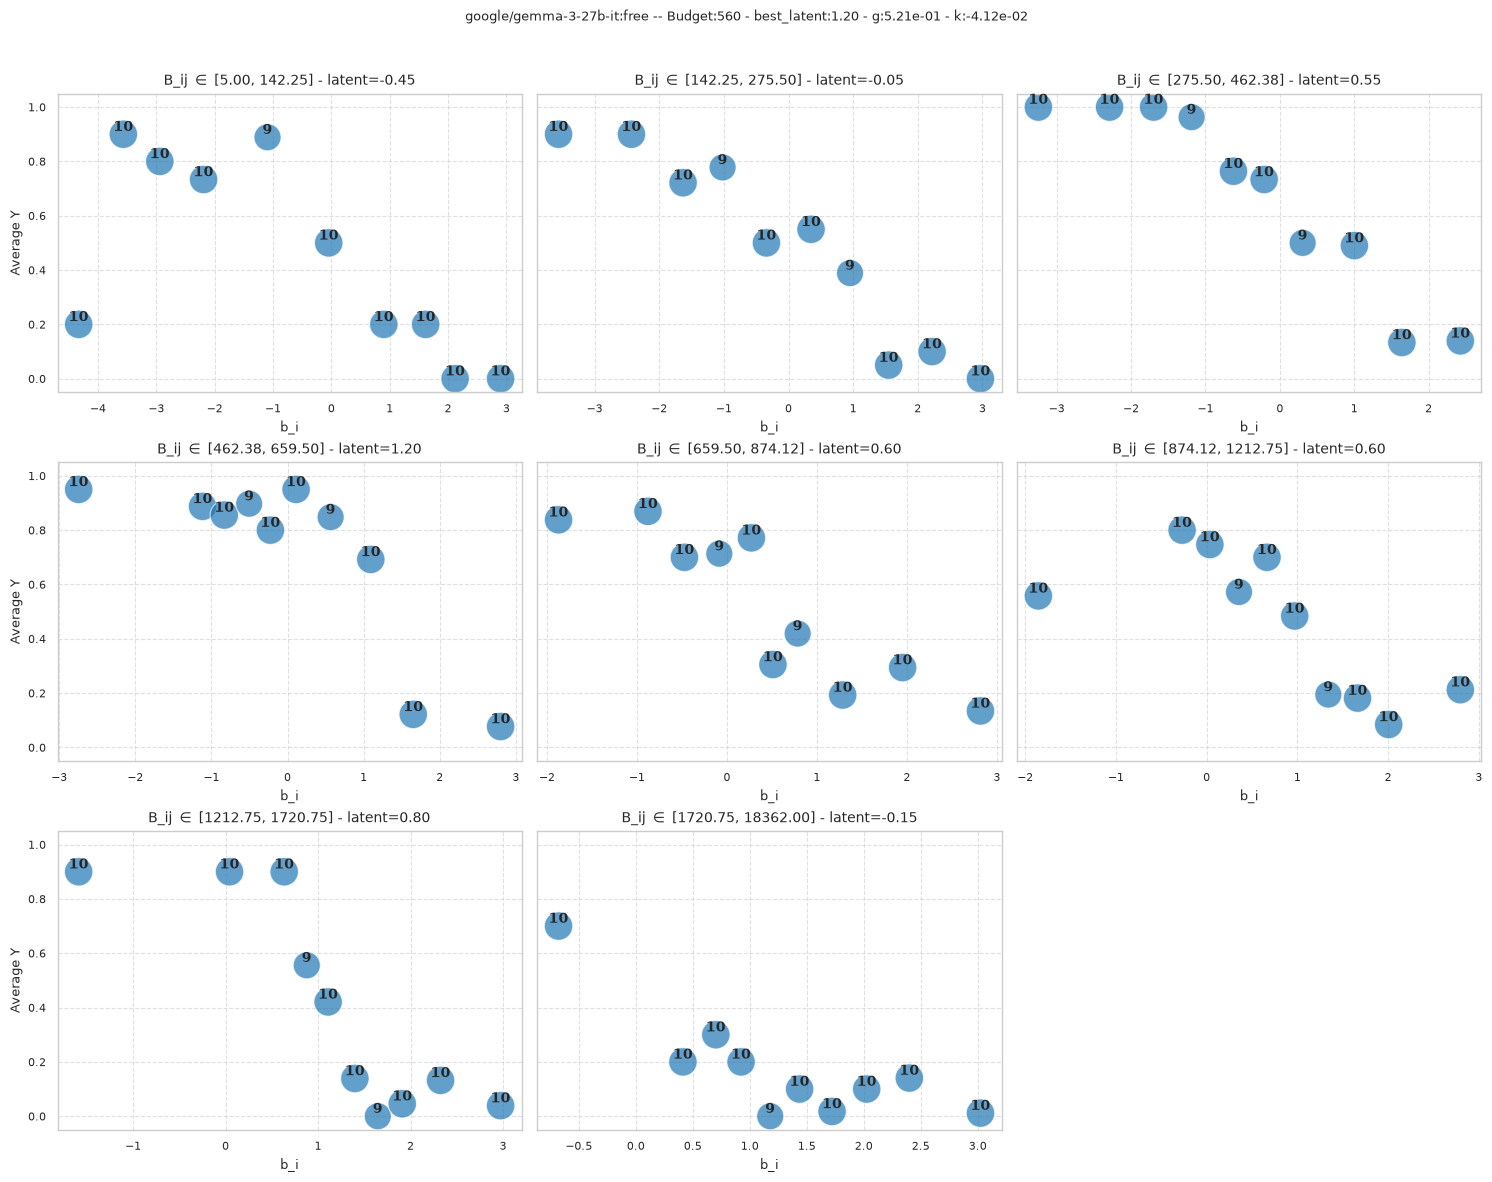

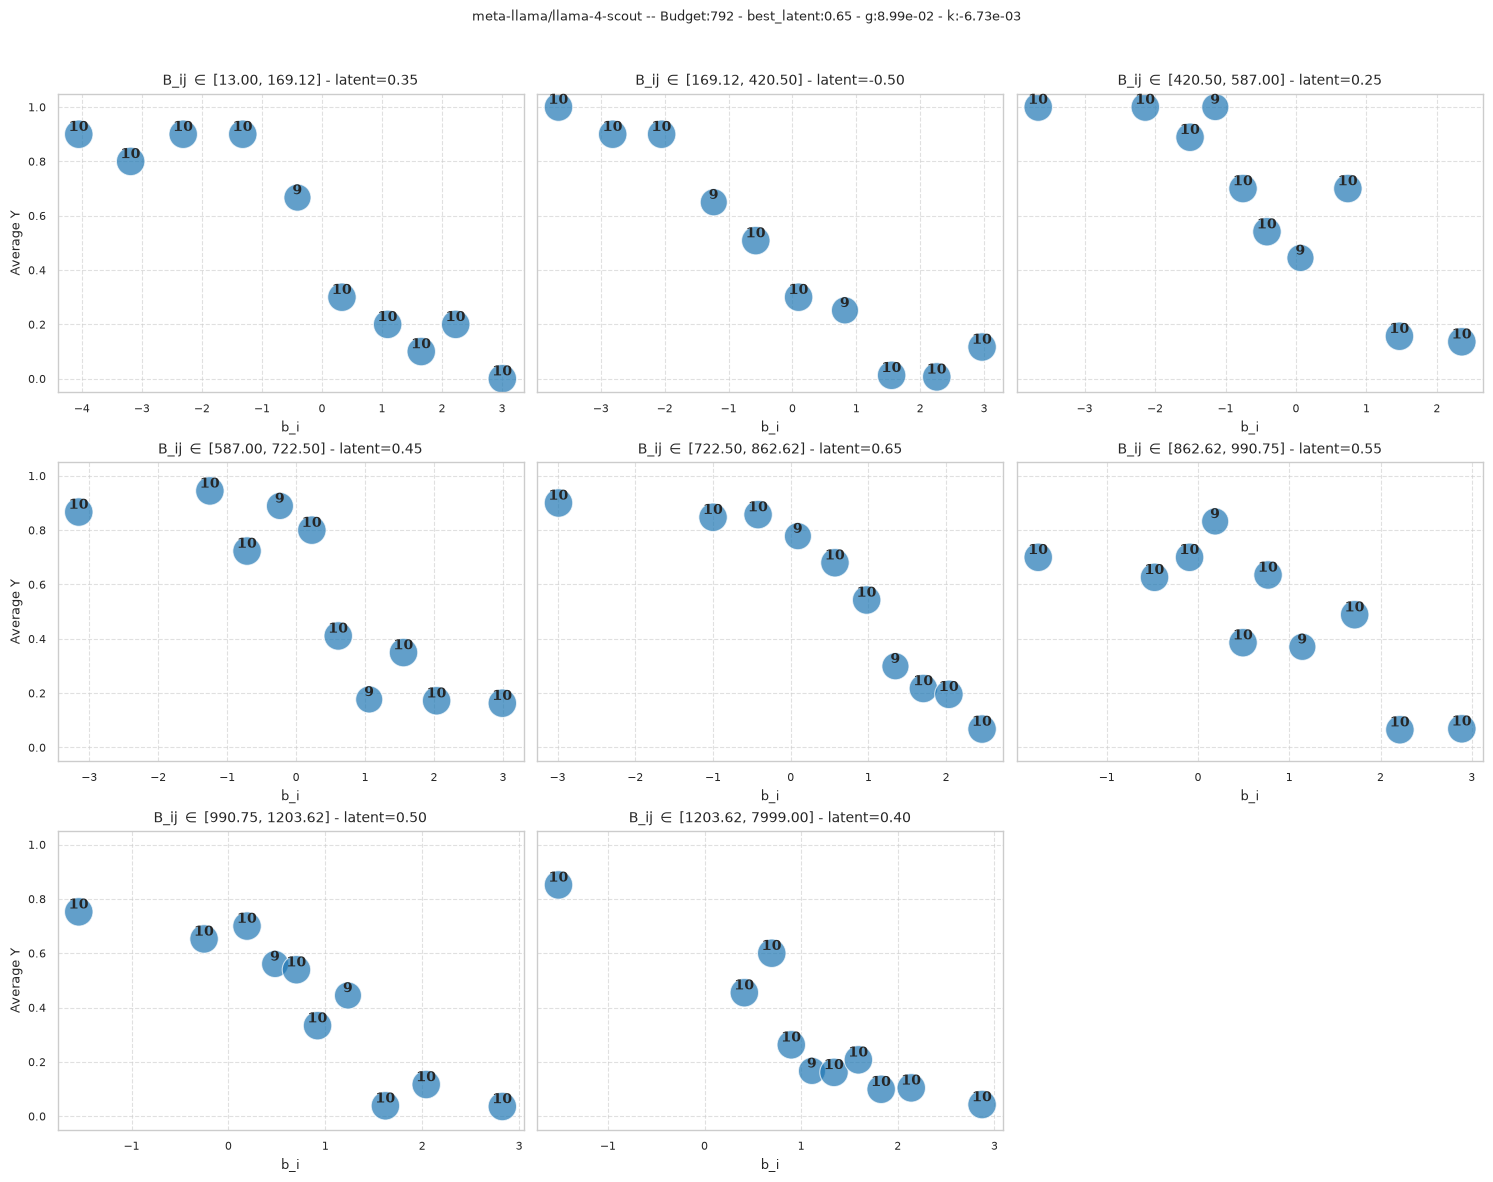

CPU times: user 21.2 s, sys: 747 ms, total: 22 s
Wall time: 22.7 s


In [17]:
%%time
best_B_j_list = []
best_latent_list = []
gamma_list = []
kappa_list = []

show_fig=False
for j in range(len(model_list)):
    ds2 = {
        'x': np.vstack([fit_results.b_i, B_ij[:,j]]).T,
        'y': Y_ij[:, j],
        'title': f'{model_list[j]}',
        'plot_function_argv' : {
            'min_points_per_bin':3, 
            'use_quantiles':True,
            'x1_label':"b_i",
            'x2_label':"B_ij",
            'y_label':"Average Y",
            'fit_object':fit_results, # valid only if slice_axis is B_ij
            }
        }
    
    if j >= 33: show_fig = True # show only some figures to save space and memory

    ret_dict = plot_sliced_bins(ds2['x'], ds2['y'], slice_axis=1, num_slices=8, num_bins_per_slice=10, title=ds2['title'],
                     **ds2['plot_function_argv'], show_fig=show_fig)
    best_B_j_list.append(ret_dict['best_B_j'])
    best_latent_list.append(ret_dict['best_latent'])
    gamma_list.append(ret_dict['gamma'])
    kappa_list.append(ret_dict['kappa'])

In [18]:
posthoc_first_pass_dict = {}
posthoc_first_pass_dict['best_B_j_list'] = best_B_j_list
posthoc_first_pass_dict['best_latent_list'] = best_latent_list
posthoc_first_pass_dict['gamma_list'] = gamma_list
posthoc_first_pass_dict['kappa_list'] = kappa_list

In [19]:
# joblib.dump(fit_results, 'data/first_pass_fit_results.pkl')
# joblib.dump(posthoc_first_pass_dict, 'data/posthoc_first_pass_dict.pkl')

In [20]:
import numpy as np
import matplotlib.pyplot as plt
from reasoning_aware_irt.utils import prob_correct_3pl

def estimate_latent2(mask, a_i, b_i, c_i, y_i, pred_theta, classic_theta):
    sub_a = a_i[mask]
    sub_b = b_i[mask]
    sub_c = c_i[mask]
    sub_y = y_i[mask][:, None] # (sub_Q,1)

    if not isinstance(pred_theta,  np.ndarray):
        pred_theta = np.array([pred_theta])
    if not isinstance(classic_theta,  np.ndarray):
        classic_theta = np.array([classic_theta])
    
    latent_k = np.linspace(-3, 4, 282)
    p_ik = prob_correct_3pl(latent_k, sub_a, sub_b, sub_c)
    ll_k = (sub_y * np.log(p_ik) + (1.0 - sub_y) * np.log(1.0 - p_ik)).sum(axis=0)  # (K,)

    p_pred = prob_correct_3pl(pred_theta, sub_a, sub_b, sub_c)
    ll_pred = (sub_y * np.log(p_pred) + (1.0 - sub_y) * np.log(1.0 - p_pred)).sum(axis=0)  # (K,)

    p_classic = prob_correct_3pl(classic_theta, sub_a, sub_b, sub_c)
    ll_classic = (sub_y * np.log(p_classic) + (1.0 - sub_y) * np.log(1.0 - p_classic)).sum(axis=0)  # (K,)
    
    return latent_k[np.argmax(ll_k)], np.max(ll_k), ll_pred[0], ll_classic[0]

def visualize_reasoning_aware_irt_v3(
    x, y, ax=None, accuracy_np=None, accuracy_threshold=0.00, apply_log=False,
    theta_base=0.0, gamma=0.3, kappa=-0.05,
    num_bins=20, min_K=3, box_plot=False,
    connect_empirical=True,
    color='black', model_name="model_x", alpha=1.0,
    theory_color='black',
    show_peak_info=True,
    a_i=None, c_i=None,
    debug=False, use_quantiles=True,
    theta_classic=None, emphasize_diff=False,
    show_graph=True, show_linear_decline=False,
    **kwargs
):
    """
    V2 Adapter function compatible with plot_combined_binned_data.
    Includes Boxplot rendering and correlation calculation.
    """
    if ax is None and show_graph:
        fig, ax = plt.subplots(figsize=(5, 3))
        is_standalone = True
    else:
        is_standalone = False

    if accuracy_np is None:
        raise ValueError("accuracy_np (correctness array) must be provided in plot_function_argv.")

    # Apply log(x + 1) if raw tokens are passed
    if apply_log:
        x = np.log1p(x)
        if model_name=='command-r-plus-08-2024': # adhoc bug fix -- break the tie of 3 / 4 / 5 tokens on this model
            eps = 1e-7
            x = x + np.random.uniform(-eps, eps, size=len(x))

    if use_quantiles:
        x_bins = np.unique(np.quantile(x, np.linspace(0, 1, num_bins + 1)))
        if len(x_bins)-1 < num_bins:
            print(f'adjust #bins from {num_bins} to {len(x_bins) - 1}')
        num_bins = len(x_bins) - 1 # np.unique might reduce length if heavy ties exist
    else:
        p02_s, p98_s = np.percentile(x, [2, 98])
        valid_mask = (x >= p02_s) & (x <= p98_s)
        x, y, a_i, c_i, accuracy_np = x[valid_mask], y[valid_mask], a_i[valid_mask], c_i[valid_mask], accuracy_np[valid_mask]
        x_bins = np.linspace(np.min(x), np.max(x), num_bins + 1)

    
    # Discretize accuracy for partial/soft scores
    correct_mask = (accuracy_np >= accuracy_threshold)

    # 1. Calculate theoretical parabola peak
    x_star = -gamma / (2 * kappa) if kappa < 0 else np.max(x)
    theta_max = theta_base + gamma * x_star + kappa * (x_star ** 2)

    # 2. Setup theoretical continuous curve
    max_plot_x = max(np.max(x), x_star) + 1.0
    min_plot_x = max(0, np.min(x) - 0.5)

    X_plot = np.linspace(min_plot_x, max_plot_x, 200)
    theta_plot = theta_base + gamma * X_plot + kappa * (X_plot ** 2)

    # 3. Process empirical data (binning)
    
    bin_centers = []
    empirical_b = []
    theoretical_b_at_centers = []
    box_data = []
    pred_llk_ratios = []
    classic_llk_ratios = []
    unified_ratios = []

    bin_idx = []
    diff_list = [] # for debug %-diff of ours vs. classic
    for i in range(num_bins):
        # Ensure the last bin includes the max value
        if i == num_bins - 1:
            in_bin = (x >= x_bins[i]) & (x <= x_bins[i+1])
        else:
            in_bin = (x >= x_bins[i]) & (x < x_bins[i+1])

        correct_in_bin = in_bin & correct_mask
        b_in_bin = y[correct_in_bin]

        bin_center = (x_bins[i] + x_bins[i+1]) / 2.0
        # if debug:
        #     print(f'{model_name} - bin_center:{bin_center} , #elements:{len(y[in_bin])}, avg_b_i:{np.mean(y[in_bin]):.2f}, avg_y_i:{np.mean(accuracy_np[in_bin]):.2f}, avg_c_i:{np.mean(c_i[in_bin]):.2f}, avg_a_i:{np.mean(a_i[in_bin]):.2f}')

        if model_name=='command-r-plus-08-2024' and i<=1:
            print(f'DEBUG: at bin{i} #elements is {len(b_in_bin)} - 3-edges are {x_bins[i]} / {x_bins[i+1]} / {x_bins[i+2]}')
        if len(b_in_bin) >= min_K:
            bin_centers.append(bin_center)
            

            # Theoretical predicted point for correlation
            pred_theta = theta_base + gamma * bin_center + kappa * (bin_center ** 2)

            bin_theta, best_llk, pred_llk, classic_llk = estimate_latent2(mask=in_bin, a_i=a_i, b_i=y, c_i=c_i, y_i=accuracy_np, pred_theta=pred_theta, classic_theta=theta_classic)      
            pred_ratio = np.exp(pred_llk)/np.exp(best_llk)
            classic_ratio = np.exp(classic_llk)/np.exp(best_llk)

            # assert (np.exp(best_llk) - np.exp(classic_llk)) >= 0, f"{model_name} - bin:{i} - best_theta:{bin_theta:.2f} - classic_theta:{theta_classic:.2f} - best llk:{best_llk:.5f} - classic llk:{classic_llk:.5f}"
            # unified_ratio = (np.exp(pred_llk) - np.exp(classic_llk)) / (np.exp(best_llk) - np.exp(classic_llk))
            
            empirical_b.append(bin_theta)

            theoretical_b_at_centers.append(pred_theta)
            pred_llk_ratios.append(pred_ratio)
            classic_llk_ratios.append(classic_ratio)
            # unified_ratios.append(unified_ratio)

            diff = np.abs(pred_theta/theta_classic)
            if emphasize_diff and (diff >= 1.1 or diff <= 0.9):
                bin_idx.append(i)
                diff_list.append(diff) # for debug
            elif not emphasize_diff:
                bin_idx.append(i)
            else:
                print(f'{model_name} - something wrong bin_idx {i} is not insert to list')
                
    # Calculate Correlation
    bin_idx = np.array(bin_idx)
    
    if len(empirical_b) > 1:
        theoretical_b_at_centers = np.array(theoretical_b_at_centers)
        empirical_b = np.array(empirical_b)

        # --- NEW CODE: Calculate linear slope after x* ---
        slope_m = np.nan
        # bin_centers_np = np.array(bin_centers)
        # post_x_mask = bin_centers_np > x_star
        
        # if np.sum(post_x_mask) > 0:
        #     x_post = bin_centers_np[post_x_mask]
        #     y_post = empirical_b[post_x_mask] 
            
        #     dx = x_post - x_star
        #     dy = y_post - theta_max
            
        #     if np.sum(dx**2) > 0:
        #         slope_m = np.sum(dx * dy) / np.sum(dx**2)
        slope_emp = np.nan
        intercept_emp = np.nan
        
        bin_centers_np = np.asarray(bin_centers, dtype=float)
        empirical_b_np = np.asarray(empirical_b, dtype=float)
        
        valid = (
            (bin_centers_np > x_star)
            & np.isfinite(bin_centers_np)
            & np.isfinite(empirical_b_np)
        )
        
        x_post = bin_centers_np[valid]
        y_post = empirical_b_np[valid]
        
        # Require enough points for a meaningful trend
        if len(x_post) >= 4 and np.ptp(x_post) > 0:
            X_design = np.column_stack([
                np.ones_like(x_post),
                x_post
            ])
        
            intercept_emp, slope_emp = np.linalg.lstsq(
                X_design, y_post, rcond=None
            )[0]
            slope_m = slope_emp
        # -------------------------------------------------

        
        corr = np.corrcoef(theoretical_b_at_centers, empirical_b)[0, 1]

        if len(bin_idx) > 0:
            try:
                mse = np.mean(np.abs(theoretical_b_at_centers[bin_idx] - empirical_b[bin_idx]))
            except:
                print(bin_idx, len(theoretical_b_at_centers), len(empirical_b))
                print(f'{model_name} - bin_idx:{bin_idx} - {diff_list}')
                assert len(bin_idx) < len(theoretical_b_at_centers) and len(bin_idx) < len(empirical_b)
            mse_static = np.mean(np.abs(theta_classic - empirical_b[bin_idx]))
        else:
            mse = 0
            mse_static = 0    
    else:
        corr = np.nan
        mse = 0
        mse_static = 0

    # Update label with correlation so it appears in the legend
    label_w_corr = f"{model_name} (r={corr:.2f})"

    # Plot theoretical curve
    if show_graph:
        ax.plot(X_plot, theta_plot, linestyle='--', color=theory_color, alpha=alpha, linewidth=2, label=label_w_corr)
        
        if bin_centers:
            if box_plot:
                # Determine a dynamic width for the boxes based on the gap between bins
                box_width = (x_bins[1] - x_bins[0]) * 0.6
        
                bp = ax.boxplot(
                    box_data, positions=bin_centers, widths=box_width,
                    patch_artist=True, manage_ticks=False,
                    boxprops=dict(facecolor=color, alpha=max(0.2, alpha-0.4), color=color),
                    capprops=dict(color=color, alpha=alpha),
                    whiskerprops=dict(color=color, alpha=alpha),
                    flierprops=dict(markeredgecolor=color, marker='.', alpha=alpha),
                    medianprops=dict(color=color, linewidth=2, alpha=alpha)
                )
            else:
                # Fallback to standard scatter plot
                ax.scatter(bin_centers, empirical_b, color=color, alpha=alpha, marker='o', s=40)
        
            if connect_empirical:
                ax.plot(bin_centers, empirical_b, color=color, alpha=max(0.2, alpha-0.2), linestyle=':')
        
        # 4. Annotations and peak lines
        if show_peak_info and kappa < 0:
            ax.axvline(x_star, color=color, linestyle='-.', alpha=max(0.1, alpha-0.4))
            ax.axhline(theta_max, color=color, linestyle='-.', alpha=max(0.1, alpha-0.4))
        
            ax.axhline(theta_classic, color='blue', linestyle='-.', alpha=max(0.1, alpha-0.4))
        
            text_str = f'$X^* \\approx {x_star:.2f}$\n$\\theta_{{max}} \\approx {theta_max:.2f}$'
            ax.text(x_star + 0.1, theta_max - 0.1, text_str, color=color, fontsize=9,
                    verticalalignment='top', alpha=0.9)
        
        if is_standalone:
            title_str = f"Correlation:{corr:.2f} - MSE:{mse:.3f} - Classic MSE:{mse_static:.3f}"
            
            if not np.isnan(slope_m):
                title_str += f"Slope (m): {slope_m:.3f} vs $\\kappa$: {kappa:.3f}"
            else:
                title_str += f"$\\kappa$: {kappa:.3f}"
                
            ax.set_title(title_str)
            ax.set_xlabel("Log-Budget $X$")
            ax.set_ylabel(r"Latent Scale ($\theta^{\mathrm{eff}}$ / $b_i$)")
            ax.legend()
            plt.tight_layout()

        # --- NEW CODE: Optional Plotting ---
        if show_linear_decline and np.isfinite(slope_emp):
            x_decline = np.linspace(x_post.min(), x_post.max(), 50)
            y_decline = intercept_emp + slope_emp * x_decline
        
            ax.plot(
                x_decline,
                y_decline,
                color="green",
                linewidth=2,
                label=f"Empirical post-peak slope = {slope_emp:.3f}",
            )
        # if show_linear_decline and not np.isnan(slope_m):
        #     x_decline = np.linspace(x_star, max_plot_x, 50)
        #     y_decline = theta_max + slope_m * (x_decline - x_star)
        #     ax.plot(x_decline, y_decline, color='green', linestyle='-', 
        #             linewidth=2, label=f"Linear Decline (m={slope_m:.2f})")

    return {
        'x_star': x_star,
        'theta_max': theta_max,
        'bin_centers': bin_centers,
        'empirical_b': empirical_b,
        'corr': corr,
        'mse': mse,
        'static_mse': mse_static,
        'pred_llk_ratio':np.mean(pred_llk_ratios),
        'classic_llk_ratio':np.mean(classic_llk_ratios),
        # 'unified_llk_ratio':np.mean(unified_ratios),
    }



In [21]:
cpath = "data/calibration_classic.pkl"
classic_results = joblib.load(cpath)
theta_classic_orig = classic_results.theta_j_mean
print(theta_classic_orig.shape)

def align_theta_scales(theta_classic: np.ndarray, theta_max: np.ndarray) -> np.ndarray:
    """
    Aligns the scale of classical IRT abilities to reasoning-aware max abilities
    using the Mean/Sigma equating method.
    """
    # 1. Standardize classical theta to have zero mean and unit variance
    z_classic = (theta_classic - np.mean(theta_classic)) / np.std(theta_classic)
    
    # 2. Scale and shift to match the moments of theta_max
    theta_classic_aligned = (z_classic * np.std(theta_max)) + np.mean(theta_max)
    
    return theta_classic_aligned

(43,)


In [22]:
gamma_j=fit_results.gamma_j
kappa_j=fit_results.kappa_j
theta_base=fit_results.theta_j_mean

x_star = np.log1p(B_ij.max(axis=0))
print(x_star.shape)

theta_max = theta_base + gamma_j * x_star
print(x_star.shape, theta_max.shape)
print(theta_classic_orig.mean(), theta_classic_orig.std())
print(theta_max.mean(), theta_max.std())

theta_classic = align_theta_scales(theta_classic_orig, theta_max)
print(theta_classic.mean(), theta_classic.std())

(42,)
(42,) (42,)
-0.7022631495327021 1.5838400538214659
-0.5390655178515684 1.2407941907420565
-0.5390655178515684 1.2407941907420565


DEBUG: at bin0 #elements is 79 - 3-edges are 1.098612208015987 / 2.944438905293646 / 4.204692651120125
DEBUG: at bin1 #elements is 78 - 3-edges are 2.944438905293646 / 4.204692651120125 / 4.695914165123134


/tmp/ipykernel_9365/1888471836.py:47: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, ax = plt.subplots(figsize=(5, 3))


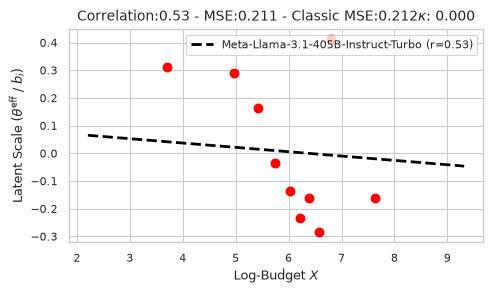

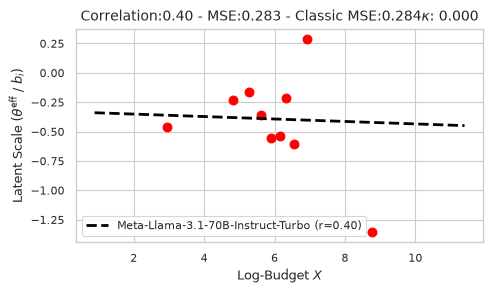

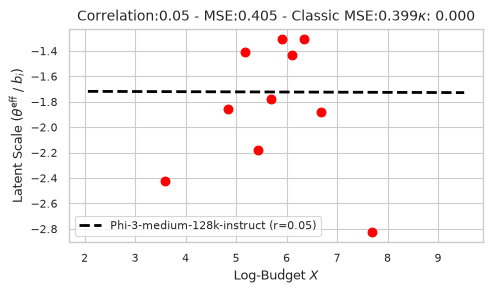

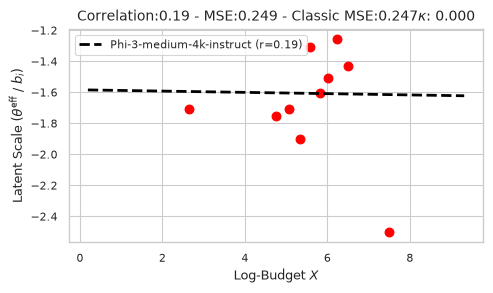

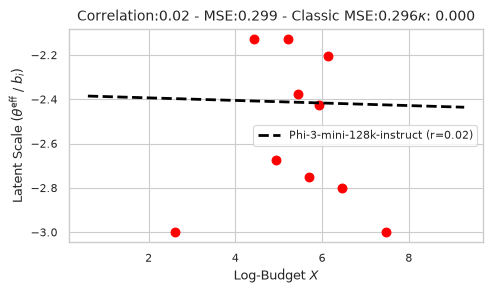

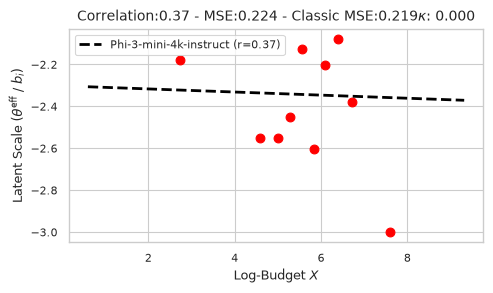

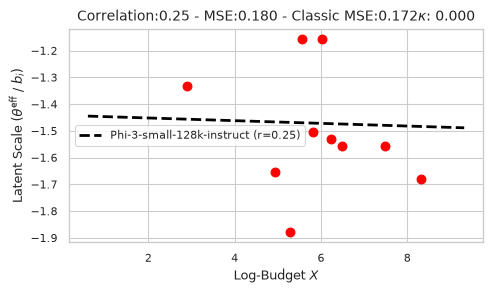

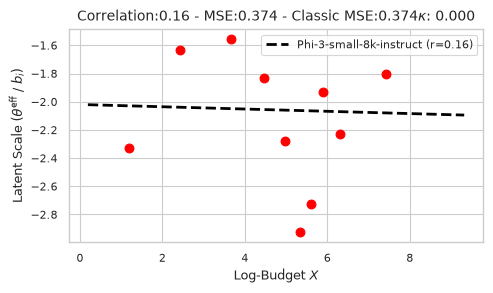

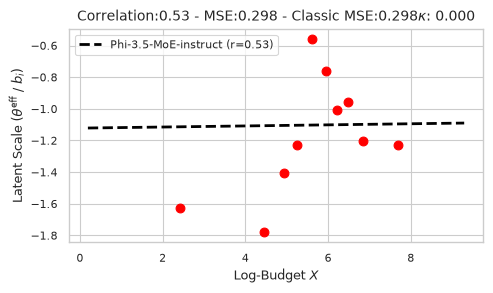

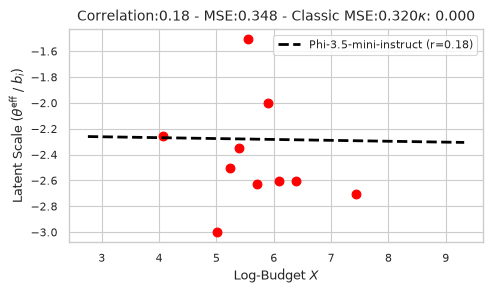

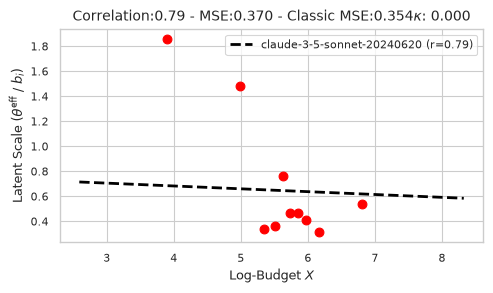

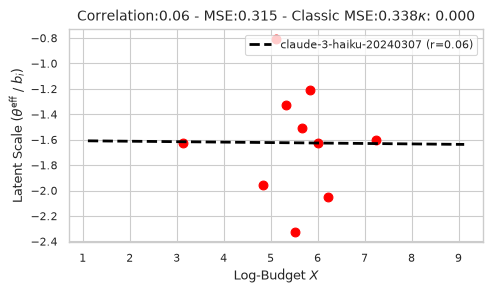

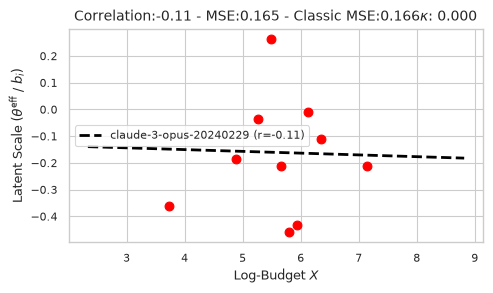

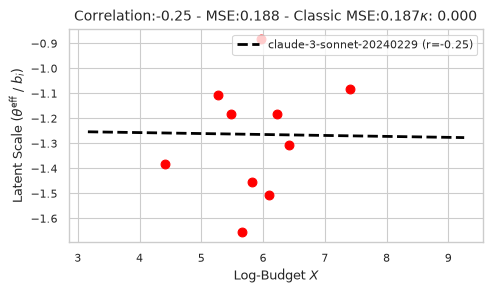

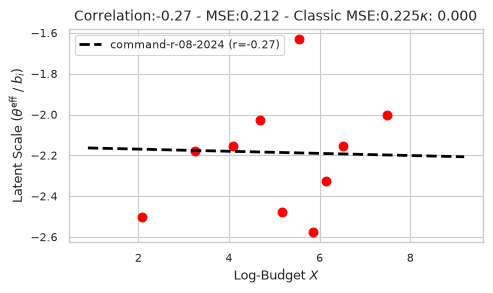

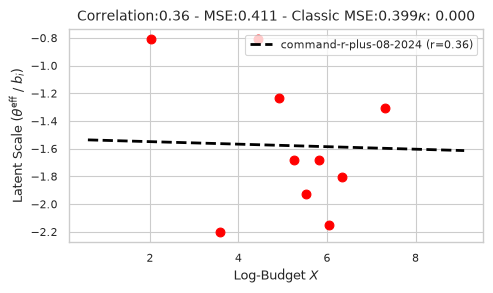

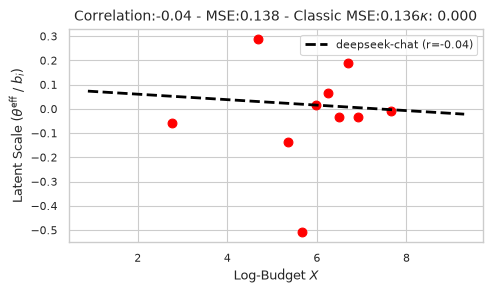

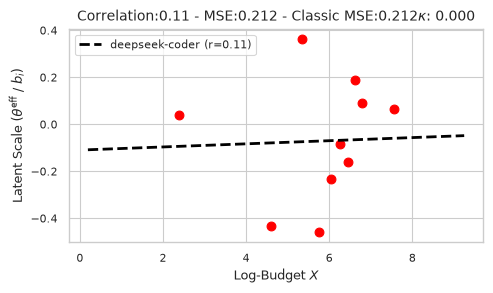

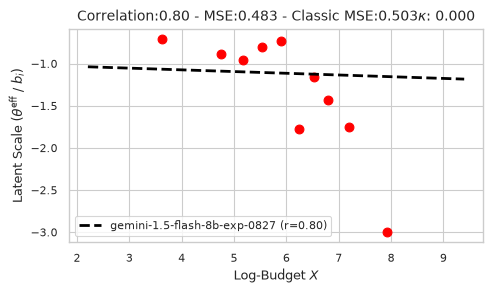

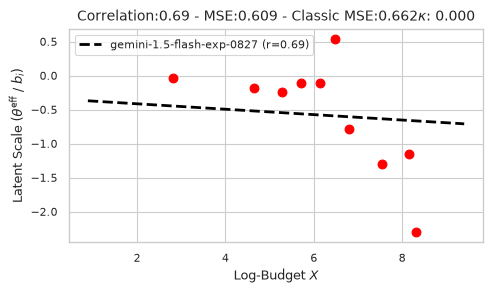

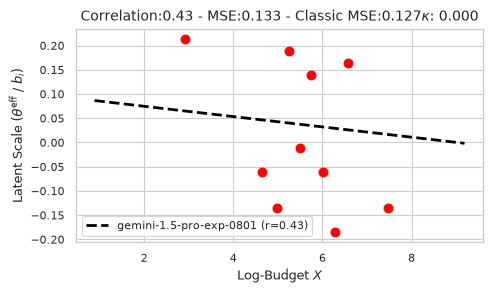

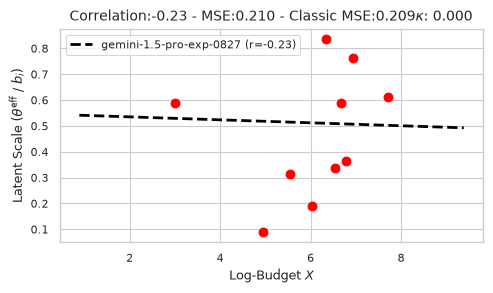

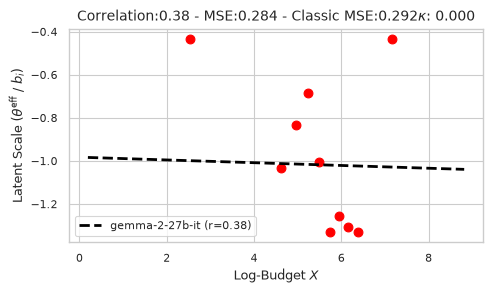

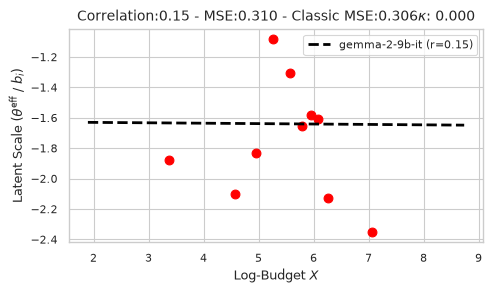

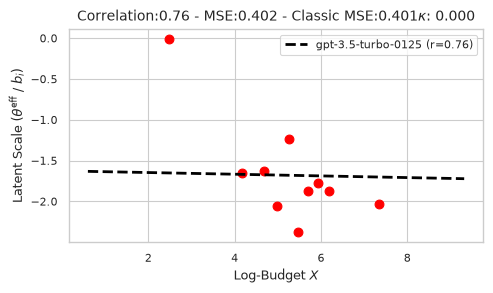

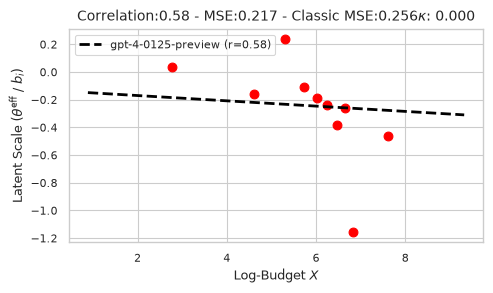

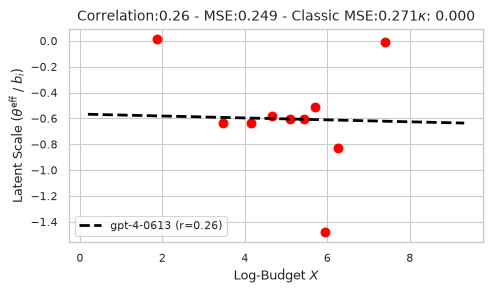

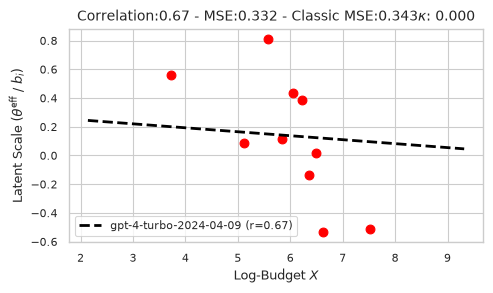

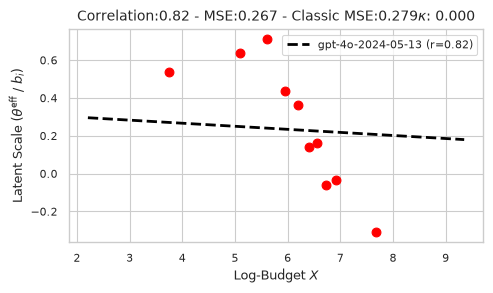

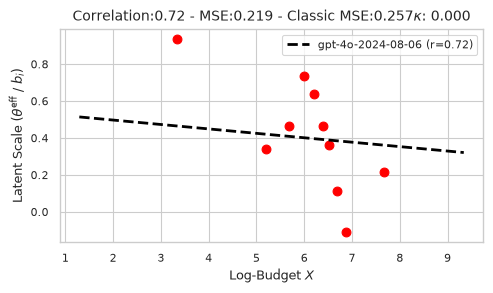

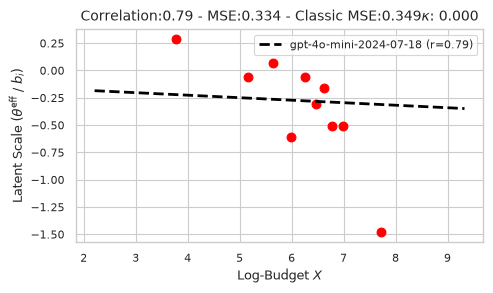

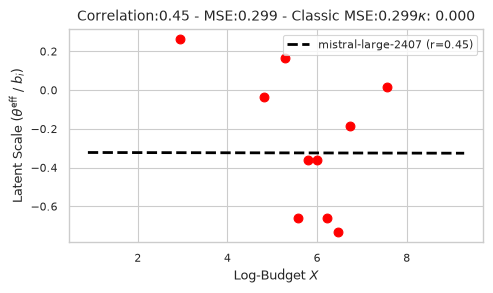

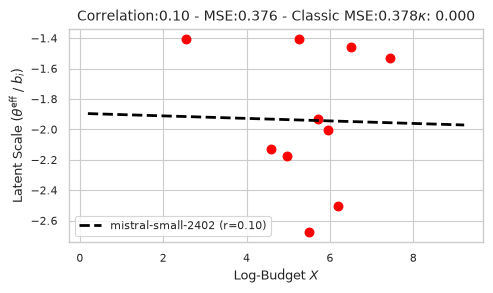

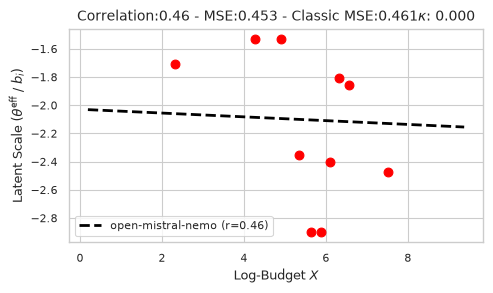

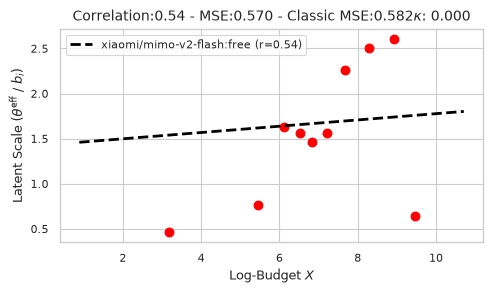

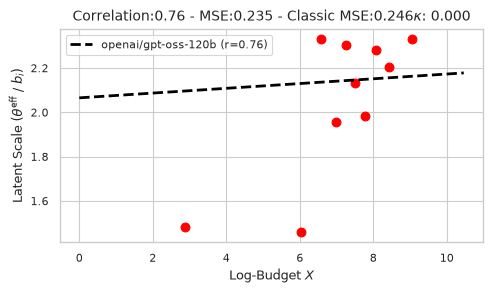

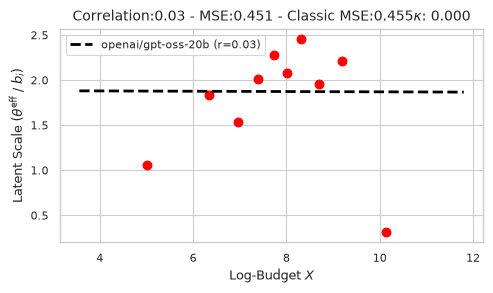

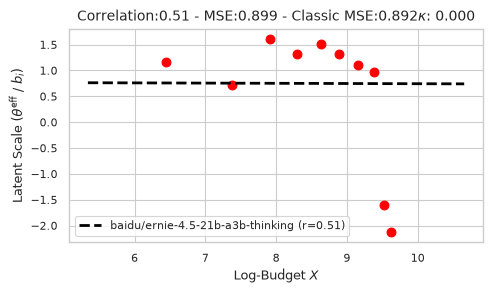

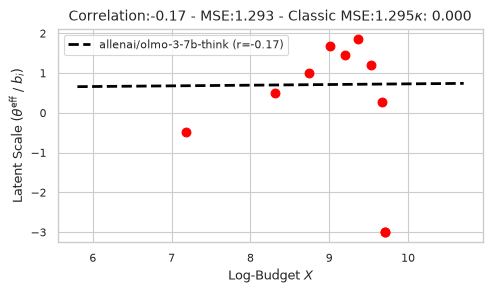

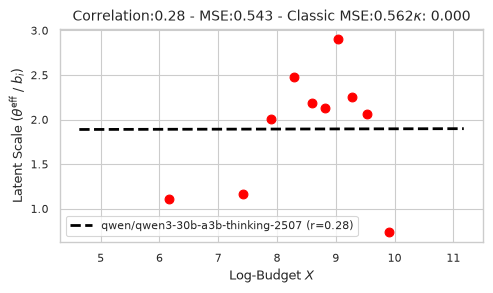

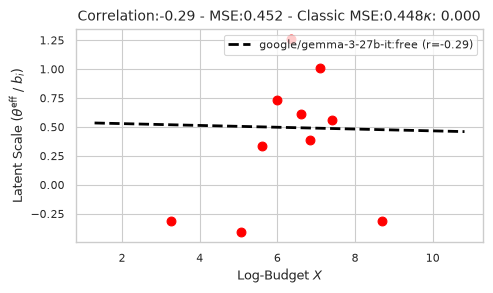

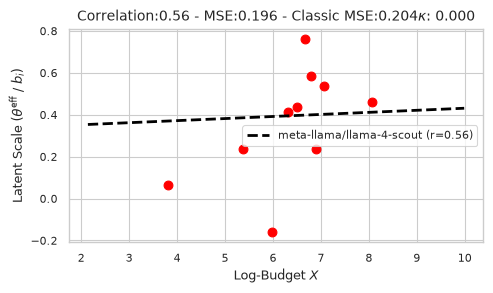

In [23]:
res_list = []
# for j in range(43):
for j in range(0,42):
    res = visualize_reasoning_aware_irt_v3(
        x=B_ij[:,j], y=fit_results.b_i, 
        accuracy_np=Y_ij[:,j], accuracy_threshold=0.0, apply_log=True,
        theta_base=fit_results.theta_j_mean[j],
        gamma=fit_results.gamma_j[j],  
        kappa=fit_results.kappa_j[j],  
        num_bins=10,
        color='red',
        connect_empirical=False,
        model_name=model_list[j],
        a_i=fit_results.a_i,
        c_i=fit_results.info['c_i'],
        theta_classic=theta_classic[j],
        show_linear_decline=True,
        # debug=True
    )
    res_list.append(res)

In [29]:
print(model_list[34])

xiaomi/mimo-v2-flash:free


In [24]:
# 10bins
corr_list = [res_list[i]['corr'] for i in range(len(res_list))]
print(np.mean(corr_list))

mse_list = [res_list[i]['mse'] for i in range(len(res_list))]
print(np.mean(mse_list))

mse_static_list = [res_list[i]['static_mse'] for i in range(len(res_list))]
print(np.mean(mse_static_list))


count=0
for i in range(len(mse_list)):
    if mse_list[i] < mse_static_list[i]:
        count += 1
print(f'Better on {count}/{len(mse_list)}' )

0.31879737196144503
0.3499130251634479
0.3551574192523972
Better on 23/42


In [26]:
corr_list = [res_list[i]['corr'] for i in range(34,len(res_list))]
print(np.mean(corr_list))

mse_list = [res_list[i]['mse'] for i in range(34,len(res_list))]
print(np.mean(mse_list))

mse_static_list = [res_list[i]['static_mse'] for i in range(34,len(res_list))]
print(np.mean(mse_static_list))

count=0
for i in range(len(mse_list)):
    if mse_list[i] < mse_static_list[i]:
        count += 1
print(f'Better on {count}/{len(mse_list)}' )

0.2778510967735238
0.5799012132327566
0.5856902814043631
Better on 6/8


In [28]:
corr_list = [res_list[i]['corr'] for i in range(34)]
print(np.mean(corr_list))

mse_list = [res_list[i]['mse'] for i in range(34)]
print(np.mean(mse_list))

mse_static_list = [res_list[i]['static_mse'] for i in range(34)]
print(np.mean(mse_static_list))

count=0
for i in range(len(mse_list)):
    if mse_list[i] < mse_static_list[i]:
        count += 1
print(f'Better on {count}/{len(mse_list)}' )

0.32843178965272063
0.29579815738243415
0.3009143928636994
Better on 17/34
